# Conformational ensemble analysis: Kmeans++ seeding based clustering and MDS embedding

This notebook illustrates two functionalities of the package `Conformational_ensemble_analysis`:

1. **Kmeans++ seeding based clustering** (`sbl-conf-ensemble-kmeanspp.exe`): $k$ representative conformations (*seeds*) are selected with the Kmeans++ seeding (EGD), refined by EGD reselection (EGD-EGD); each conformation is assigned to its nearest seed, which defines $k$ clusters. Scanning $k=1,\dots,k_{\max}$ and locating the elbow of the curve $k \mapsto \sum_i \min_j d(c_i, s_j)$ suggests a number of clusters.
2. **Embedding via MDS** (`sbl-mds.exe`, package `Dimensionality_reduction`): the ensemble is embedded in 2D/3D by landmark multi-dimensional scaling, the seeds being the landmarks.

The distance between conformations is the least RMSD (lRMSD) computed on backbone atoms.

**Input:** `data/loop_3mme_A_93_102_ensemble_200.pdb`, a multi-model PDB file with 200 conformations of the 30-residue CDR-H3 loop 93-102 (with insertion codes 100A-100T) of chain A of PDB 3MME, generated with the package `Loop_sampling`.

**Requirements:** `sbl-conf-ensemble-kmeanspp.exe` and `sbl-mds.exe` on the `PATH`; Python modules `SBL.Conformational_ensemble_kmeanspp` and `SBL.MDS_plots`.

In [2]:
import shutil
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from src.Conformational_ensemble_kmeanspp import ConformationalEnsembleKmeansppRunner


ENSEMBLE = Path("../data/loop_3mme_A_93_102_ensemble_200.pdb").resolve()
RESIDS = "93-102"      # residue range; insertion codes (100A-100T) are included
ATOMS = "N,CA,C,O"     # backbone atoms, as used by sbl-mds.exe --atom-mode backbone
K_MAX = 15             # scan k = 1..K_MAX
RANDOM_SEED = 42

runner = ConformationalEnsembleKmeansppRunner(root_results="results/kmeanspp_mds")
print(f"ensemble: {ENSEMBLE.name}, {ENSEMBLE.read_text().count('MODEL')} conformations")

ensemble: loop_3mme_A_93_102_ensemble_200.pdb, 200 conformations


## 1. Kmeans++ seeding based clustering

### 1.1 Choosing $k$: scan and elbow

For each $k \le$ `K_MAX`, the EGD-EGD seeding selects $k$ seeds and reports the total distance of the conformations to their nearest seed. The elbow is the $k$ minimizing the residual sum of squares of a two-piece linear fit of this curve.


Stage: seeding
  output directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_scan
  log: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_scan/sbl-conf-ensemble-kmeanspp.log
  directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_scan


**Selected seeds** were not written. Rerun `run_seeding(..., k=<number_of_seeds>)` to produce `seeding_seeds.csv`.

**Suggested k (piecewise-linear SSE elbow): 2**  — rerun `run_seeding(..., k=2, save_pdbs=True)` to materialise the seed PDBs.

**k-scan plot** saved to `/home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_scan/seeding_k_scan.png`

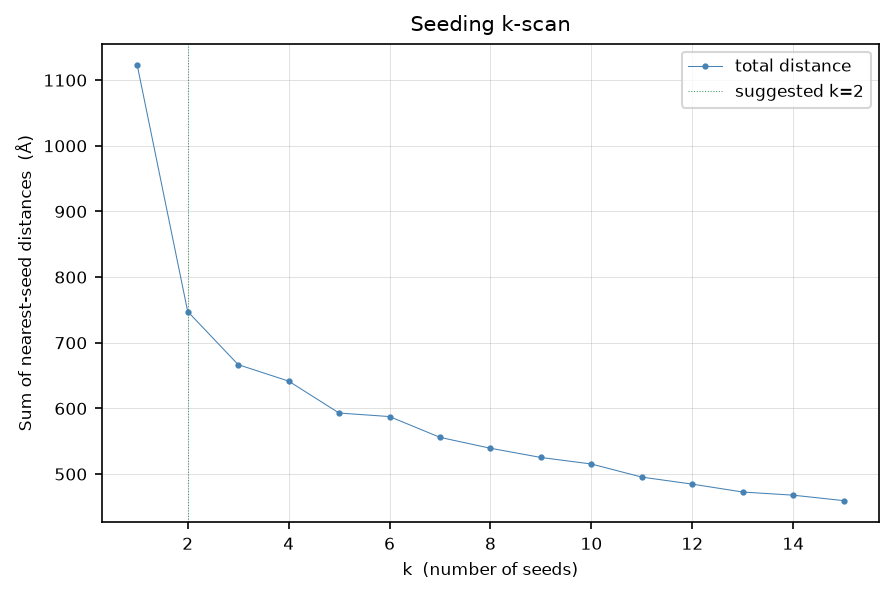

suggested number of clusters: k = 2


In [3]:
scan_run = runner.run_seeding(
    ENSEMBLE, RESIDS,
    odpath=runner.root_results / "seeding_scan",
    scan_k_max=K_MAX, method="EGD-EGD", metric="lrmsd",
    atoms=ATOMS, random_seed=RANDOM_SEED,
)
scan = runner.analyze_seeding(scan_run)
K = scan["suggested_k"]
print(f"suggested number of clusters: k = {K}")

### 1.2 Seeds and clusters for the selected $k$

The seeds are written as PDB files (`seeds/seed_<rank>_index_<conformation index>.pdb`), and the nearest-seed assignment of every conformation to `seeding_assignments.csv`.


Stage: seeding
  output directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k2
  log: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k2/sbl-conf-ensemble-kmeanspp.log
  directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k2


**Selected seeds** (k = 2) — `/home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k2/seeding_seeds.csv`

seed,index,filepath
0,73,/home/guillaume/clustering_part/data/loop_3mme_A_93_102_ensemble_200.pdb#model=74
1,101,/home/guillaume/clustering_part/data/loop_3mme_A_93_102_ensemble_200.pdb#model=102


**Clusters** (nearest-seed assignment) — `/home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k2/seeding_assignments.csv`

seed,seed_index,cluster_size,mean_distance_to_seed,max_distance_to_seed
0,73,86,3.584,4.826
1,101,114,3.854,4.750


**Suggested k (piecewise-linear SSE elbow): 2**  — rerun `run_seeding(..., k=2, save_pdbs=True)` to materialise the seed PDBs.

**k-scan plot** saved to `/home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k2/seeding_k_scan.png`

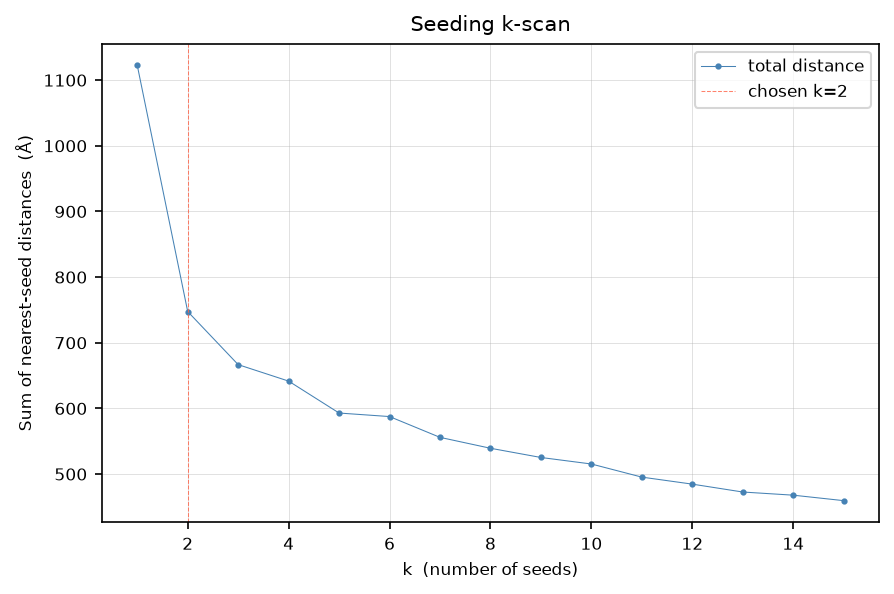

cluster sizes: {0: 86, 1: 114}


In [4]:
seeding_run = runner.run_seeding(
    ENSEMBLE, RESIDS,
    odpath=runner.root_results / f"seeding_k{K}",
    k=K, scan_k_max=K_MAX, method="EGD-EGD", metric="lrmsd",
    atoms=ATOMS, random_seed=RANDOM_SEED, save_pdbs=True,
)
clustering = runner.analyze_seeding(seeding_run)
print("cluster sizes:", clustering["cluster_sizes"])

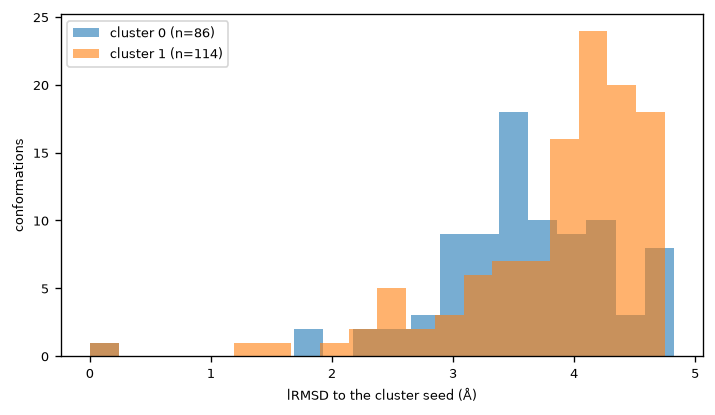

In [5]:
# Distribution of the lRMSD of each conformation to its seed, per cluster.
assignments = clustering["assignments"]
fig, ax = plt.subplots(figsize=(6, 3.5), dpi=120)
for seed in sorted(clustering["cluster_sizes"]):
    d = [float(r["distance"]) for r in assignments if int(r["seed"]) == seed]
    ax.hist(d, bins=20, alpha=0.6, label=f"cluster {seed} (n={len(d)})")
ax.set_xlabel("lRMSD to the cluster seed (Å)")
ax.set_ylabel("conformations")
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

## 2. Embedding via MDS

Landmark MDS: the classical MDS is computed on the landmarks (the seeds), and the remaining conformations are placed by triangulation with respect to the landmarks. The scree plot shows the eigenvalues of the double-centered squared-distance matrix.

## 2. Embedding via MDS

### 2.1 Classical MDS of the ensemble

Classical MDS embeds all conformations from the matrix of pairwise lRMSD: the double-centered matrix of squared distances is diagonalized, and the top eigenvectors scaled by the square root of the eigenvalues give the coordinates. The scree plot shows how much of the geometry the first axes capture. Below, the 2D embedding is colored by Kmeans++ cluster, the seeds being marked by stars.

Sample labels `sample_model_<n>` refer to the $n$-th MODEL of the input (1-based), whereas conformation indices in `seeding_assignments.csv` are 0-based.


Stage: MDS
  output directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_loop_3mme_A_93_102_ensemble_200_classical
  log: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_loop_3mme_A_93_102_ensemble_200_classical/sbl-mds.log
  directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_loop_3mme_A_93_102_ensemble_200_classical


**MDS — mode `classical`** (200 points) — `/home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_loop_3mme_A_93_102_ensemble_200_classical`

**embedding_2d.png**

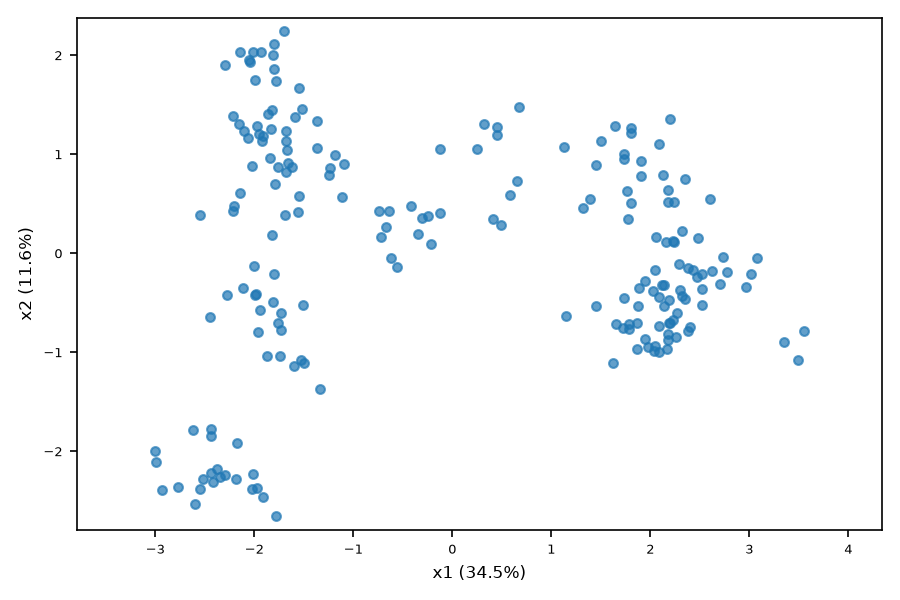

**embedding_2d_heatmap.png**

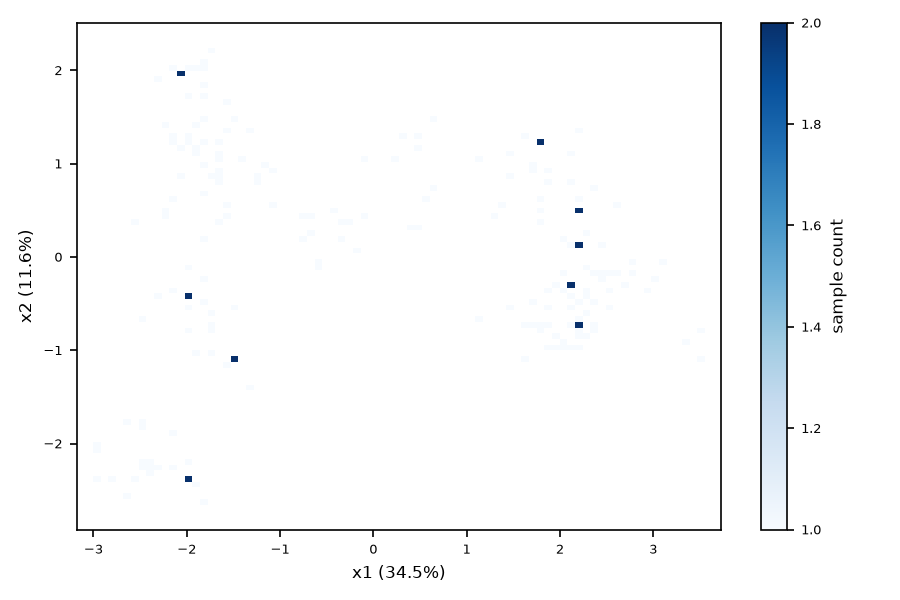

**embedding_3d.png**

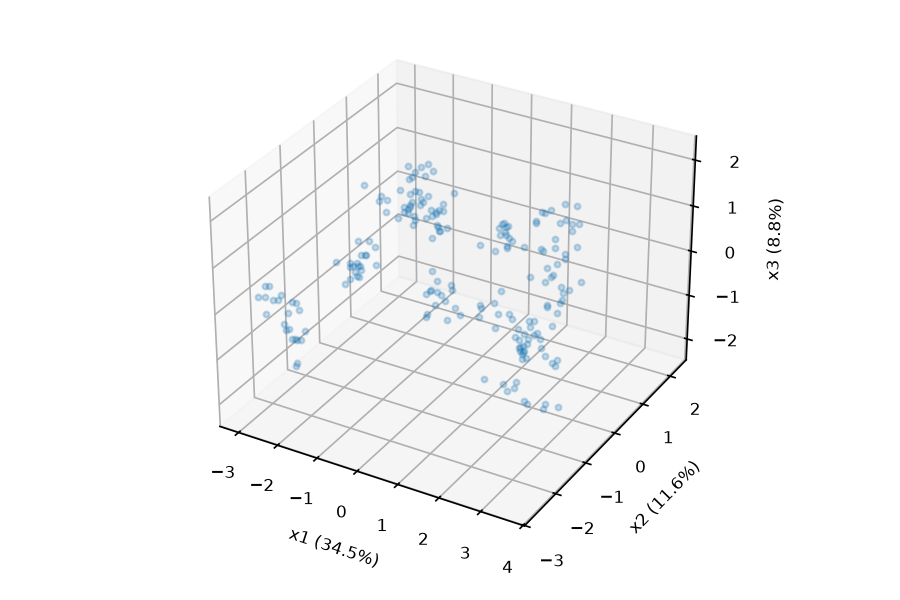

**scree.png**

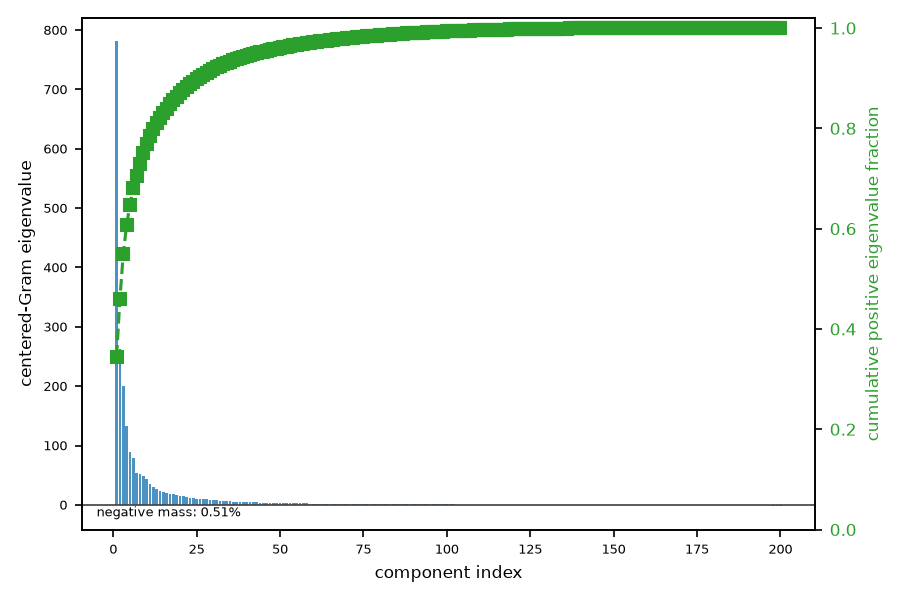

In [6]:
classical_run = runner.run_mds(ENSEMBLE, mode="classical", target_dim=3, atom_mode="backbone")
classical = runner.analyze_mds(classical_run)

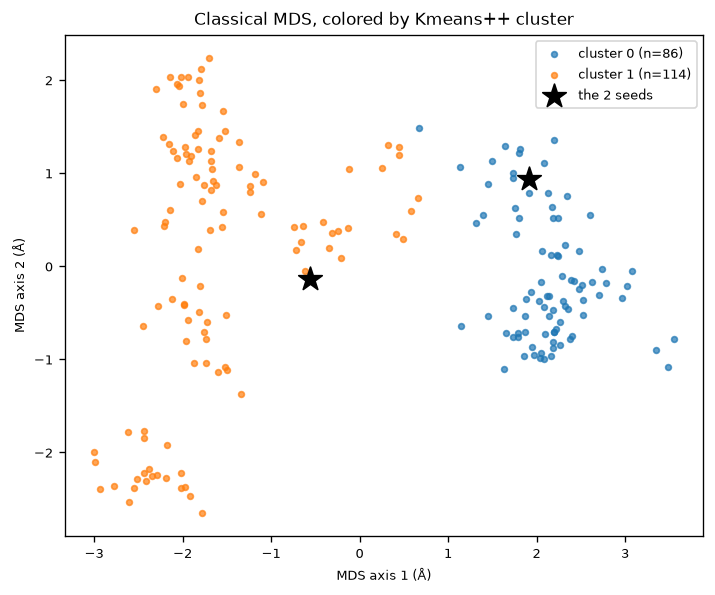

In [7]:
def plot_embedding_by_cluster(result, title):
    """2D embedding colored by Kmeans++ cluster; seeds and landmarks highlighted."""
    cluster_of_model = {int(r["index"]) + 1: int(r["seed"]) for r in assignments}
    seed_models = {int(r["index"]) + 1 for r in clustering["seeds_df"]}
    labels = list(result.labels_2d)
    X = np.asarray(result.X2)
    model = {i: int(lab.rsplit("_", 1)[1]) for i, lab in enumerate(labels)
             if lab.startswith("sample_model_")}
    fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
    cmap = plt.get_cmap("tab10")
    for seed in sorted(clustering["cluster_sizes"]):
        idx = [i for i, m in model.items() if cluster_of_model[m] == seed]
        ax.scatter(X[idx, 0], X[idx, 1], s=12, color=cmap(seed), alpha=0.7,
                   label=f"cluster {seed} (n={len(idx)})")
    idx = [i for i, m in model.items() if m in seed_models]
    ax.scatter(X[idx, 0], X[idx, 1], s=220, marker="*", color="black", label=f"the {K} seeds")
    if result.is_landmark_2d is not None and np.any(result.is_landmark_2d):
        lm = np.asarray(result.is_landmark_2d, dtype=bool)
        ax.scatter(X[lm, 0], X[lm, 1], s=60, marker="D", facecolors="none",
                   edgecolors="black", label=f"{lm.sum()} landmarks")
    ax.set_xlabel("MDS axis 1 (Å)")
    ax.set_ylabel("MDS axis 2 (Å)")
    ax.set_title(title)
    ax.legend(fontsize=8)
    fig.tight_layout()
    display(fig)  # MDS_plots selects the non-interactive Agg backend
    plt.close(fig)


plot_embedding_by_cluster(classical["result"], "Classical MDS, colored by Kmeans++ cluster")

### 2.2 Landmark MDS with Kmeans++ seeds as landmarks

Classical MDS needs all $n^2$ pairwise distances. Landmark MDS only needs the distances to $L \ll n$ landmarks: classical MDS is run on the landmarks, and every other conformation is placed by distance-based triangulation. Since $L$ landmarks span at most $L-1$ dimensions, the landmarks should be well spread and more numerous than the target dimension; Kmeans++ seeds are a natural choice. Here we use `K_MAX` seeds as landmarks.


Stage: seeding
  output directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k15_landmarks
  log: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k15_landmarks/sbl-conf-ensemble-kmeanspp.log
  directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/seeding_k15_landmarks

Stage: MDS
  output directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_landmark_k15
  log: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_landmark_k15/sbl-mds.log
  directory: /home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_landmark_k15


**MDS — mode `landmark-seeding`** (215 points, 15 landmarks) — `/home/guillaume/clustering_part/notebooks/results/kmeanspp_mds/mds_landmark_k15`

**embedding_2d.png**

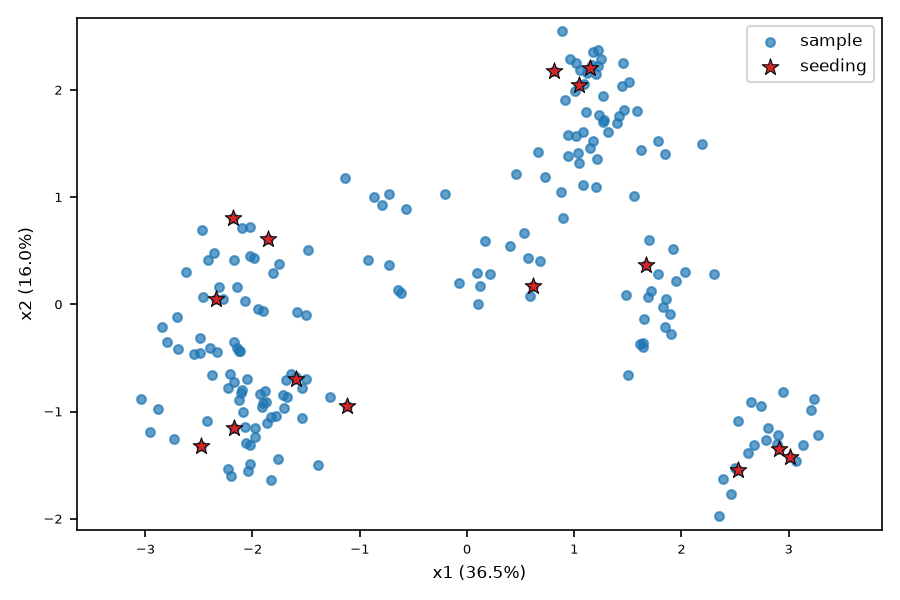

**embedding_2d_heatmap.png**

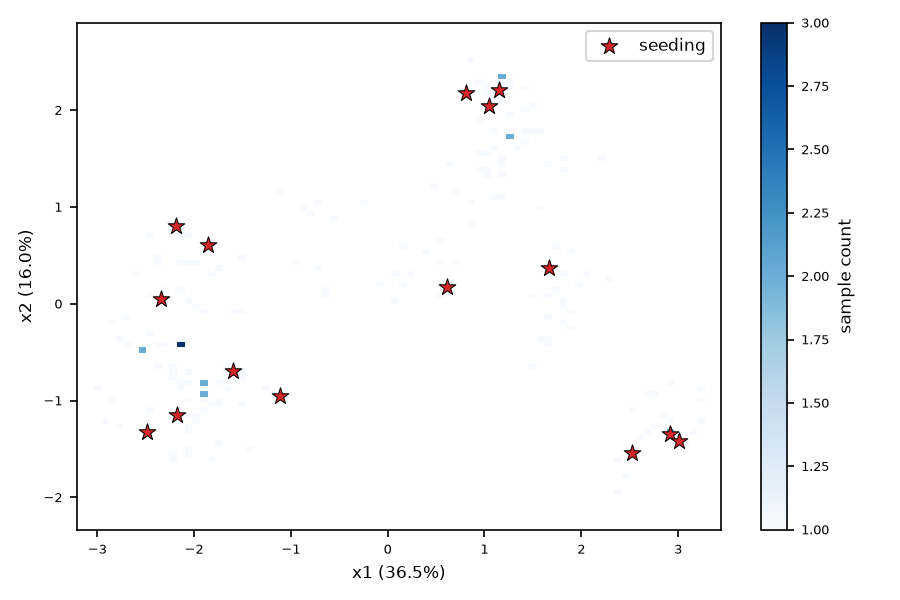

**embedding_3d.png**

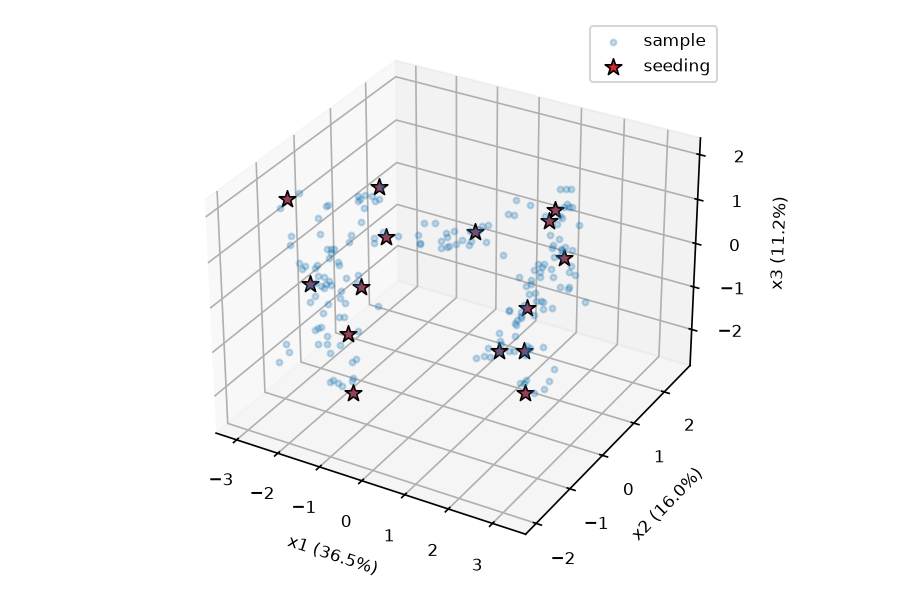

**scree.png**

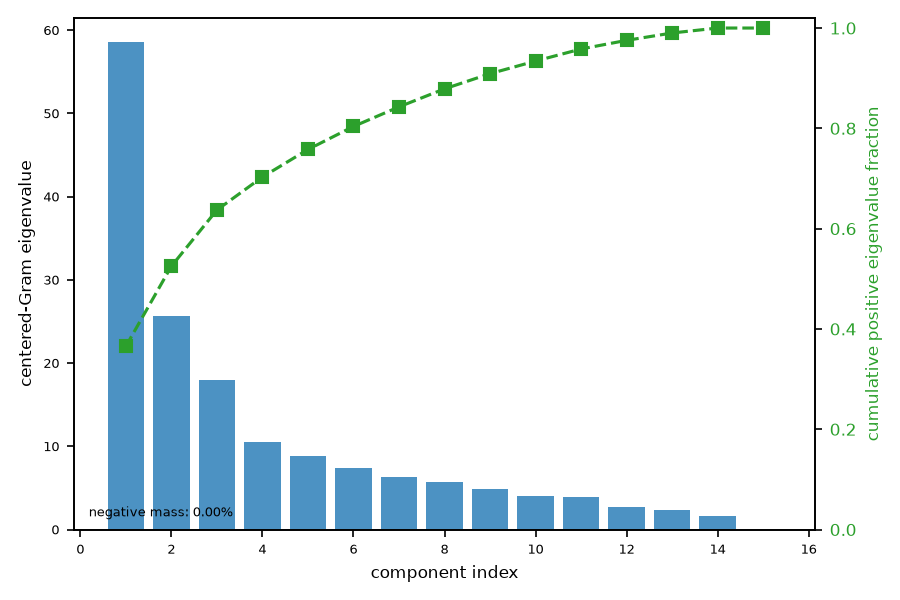

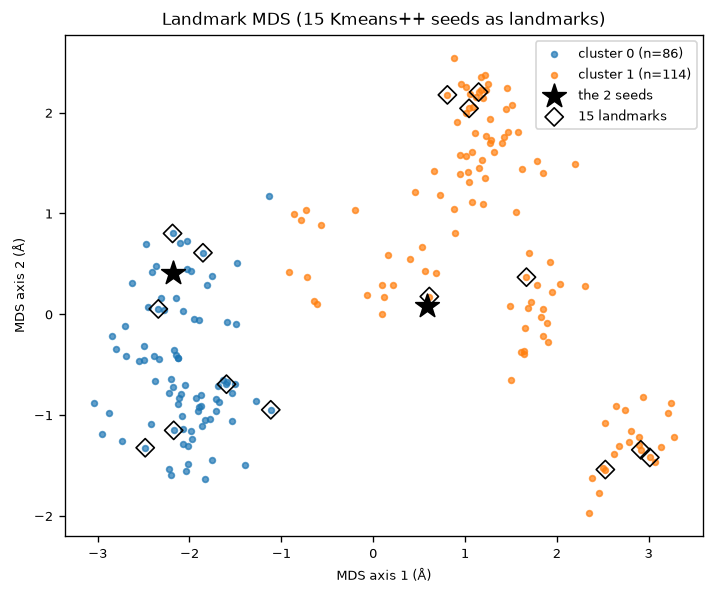

In [8]:
landmark_seeding_run = runner.run_seeding(
    ENSEMBLE, RESIDS,
    odpath=runner.root_results / f"seeding_k{K_MAX}_landmarks",
    k=K_MAX, scan_k_max=0, method="EGD-EGD", metric="lrmsd",
    atoms=ATOMS, random_seed=RANDOM_SEED, save_pdbs=True,
)
landmark_run = runner.run_mds(
    ENSEMBLE,
    mode="landmark-seeding",
    seeding_run=landmark_seeding_run,
    odpath=runner.root_results / f"mds_landmark_k{K_MAX}",
    target_dim=3,
    atom_mode="backbone",
)
landmark = runner.analyze_mds(landmark_run, show_labels=False)
plot_embedding_by_cluster(landmark["result"], f"Landmark MDS ({K_MAX} Kmeans++ seeds as landmarks)")